In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
import seaborn as sns
from IPython.display import display

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, adjusted_rand_score, pairwise_distances,
    accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import (
    GroupShuffleSplit, StratifiedGroupKFold,
    cross_validate, GridSearchCV
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 170)
sns.set_theme(style='whitegrid', context='notebook')

font_names = {f.name for f in font_manager.fontManager.ttflist}
for kr_font in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR']:
    if kr_font in font_names:
        plt.rcParams['font.family'] = kr_font
        break
plt.rcParams['axes.unicode_minus'] = False
# 일부 버전 LightGBM + Pipeline 조합에서 나타나는 무해한 경고 제거
warnings.filterwarnings('ignore', message='X does not have valid feature names, but LGBMClassifier')
print('라이브러리 불러오기 성공')

라이브러리 불러오기 성공


In [2]:
CSV_PATH = Path('Per 36 Minutes.csv')
if not CSV_PATH.exists():
    CSV_PATH = Path('../Per 36 Minutes.csv')  
assert CSV_PATH.exists()

START_SEASON = 2019
END_SEASON = 2026
OUR_TEAM = 'GSW'
TARGET_PLAYER_ID = 'curryst01'
MIN_SEASON_MINUTES = 300
RECENT_DECAY = 0.80
TOP_N = 5

print('데이터:', CSV_PATH.name)
print(f'분석 기간: {START_SEASON}~{END_SEASON} / 팀: {OUR_TEAM} / 대상 ID: {TARGET_PLAYER_ID}')

데이터: Per 36 Minutes.csv
분석 기간: 2019~2026 / 팀: GSW / 대상 ID: curryst01


In [3]:
raw = pd.read_csv(CSV_PATH)
print('원본 크기 (행, 열):', raw.shape)
display(raw.head(5))
print('\n데이터 타입:')
display(raw.dtypes.rename('dtype').to_frame())
print('\n결측치가 있는 컬럼:')
missing_raw = pd.DataFrame({'결측 수': raw.isna().sum(), '결측 비율(%)': raw.isna().mean()*100})
display(missing_raw[missing_raw['결측 수']>0].sort_values('결측 수', ascending=False).round(2))
print('완전히 같은 행의 중복 수:', raw.duplicated().sum())

원본 크기 (행, 열): (32256, 32)


,season,lg,player,player_id,age,team,pos,g,gs,mp,fg_per_36_min,fga_per_36_min,fg_percent,x3p_per_36_min,x3pa_per_36_min,x3p_percent,x2p_per_36_min,x2pa_per_36_min,x2p_percent,e_fg_percent,ft_per_36_min,fta_per_36_min,ft_percent,orb_per_36_min,drb_per_36_min,trb_per_36_min,ast_per_36_min,stl_per_36_min,blk_per_36_min,tov_per_36_min,pf_per_36_min,pts_per_36_min
0,2026,NBA,Precious Achiuwa,achiupr01,26.0,SAC,C,73,57.0,1745,6.5,12.3,0.528,0.6,2.0,0.278,6.0,10.3,0.577,0.551,1.6,2.9,0.554,3.7,6.5,10.2,2.1,1.3,1.0,1.3,2.5,15.2
1,2026,NBA,Steven Adams,adamsst01,32.0,HOU,C,32,11.0,730,3.5,6.9,0.504,0.0,0.0,NaN,3.5,6.9,0.504,0.504,2.3,4.0,0.580,7.2,6.5,13.6,2.4,1.1,1.0,1.7,2.7,9.2
2,2026,NBA,Bam Adebayo,adebaba01,28.0,MIA,C,73,73.0,2365,7.7,17.4,0.442,1.9,6.1,0.318,5.8,11.3,0.509,0.497,5.0,6.4,0.778,2.3,8.9,11.1,3.5,1.3,0.7,1.8,1.9,22.3
3,2026,NBA,Ochai Agbaji,agbajoc01,25.0,2TM,SG,62,13.0,973,4.5,10.4,0.436,1.3,4.7,0.266,3.3,5.6,0.579,0.496,1.3,1.6,0.837,1.7,3.5,5.2,1.7,0.9,0.6,1.1,3.4,11.6
4,2026,NBA,Ochai Agbaji,agbajoc01,25.0,TOR,SG,42,13.0,650,4.0,9.4,0.424,0.7,3.6,0.185,3.3,5.8,0.571,0.459,1.4,1.6,0.862,1.8,3.4,5.3,1.7,0.9,0.6,1.1,4.2,10.0



데이터 타입:


,dtype
season,int64
lg,str
player,str
player_id,str
age,float64
team,str
pos,str
g,int64
gs,float64
mp,int64



결측치가 있는 컬럼:


,결측 수,결측 비율(%)
x3p_percent,9542,29.58
gs,7072,21.92
x2p_percent,5507,17.07
e_fg_percent,5414,16.78
x3pa_per_36_min,5276,16.36
x2p_per_36_min,5275,16.35
x2pa_per_36_min,5275,16.35
x3p_per_36_min,5275,16.35
tov_per_36_min,4558,14.13
stl_per_36_min,4524,14.03


완전히 같은 행의 중복 수: 0


필터 전: 32256 행 → 필터 후: 5758 행


,season,행수,고유선수
0,2019,708,530
1,2020,651,529
2,2021,705,540
3,2022,812,605
4,2023,679,539
5,2024,735,572
6,2025,735,569
7,2026,733,582


포지션 분포: {'SG': 1405, 'PF': 1113, 'SF': 1090, 'C': 1085, 'PG': 1064, nan: 1}


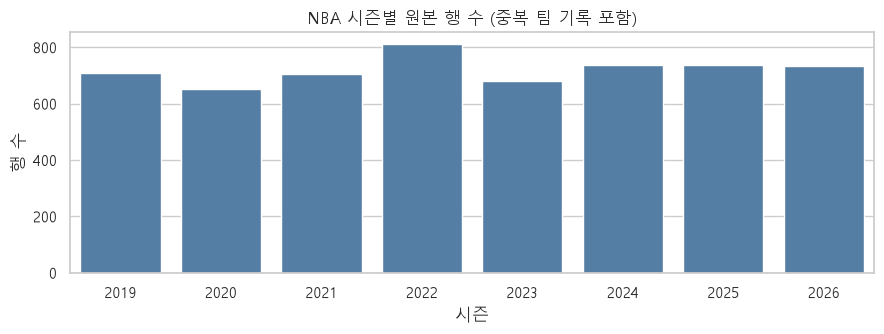

In [4]:
nba = raw.loc[raw['season'].between(START_SEASON, END_SEASON) & raw['lg'].eq('NBA')].copy()
print('필터 전:', len(raw), '행 → 필터 후:', len(nba), '행')
display(nba.groupby('season').agg(행수=('player_id','size'), 고유선수=('player_id','nunique')).reset_index())
print('포지션 분포:',nba['pos'].value_counts(dropna=False).to_dict())
plt.figure(figsize=(9,3.5))
sns.countplot(data=nba, x='season', order=sorted(nba['season'].unique()), color='#477eb3')
plt.title('NBA 시즌별 원본 행 수 (중복 팀 기록 포함)')
plt.xlabel('시즌');plt.ylabel('행 수');plt.tight_layout();plt.show()

In [5]:
missing_nba = pd.DataFrame({'결측 수':nba.isna().sum(), '비율(%)':nba.isna().mean().mul(100).round(2)})
display(missing_nba[missing_nba['결측 수']>0].sort_values('결측 수', ascending=False))
checks = [
    ('x3p_percent','x3pa_per_36_min'),
    ('ft_percent','fta_per_36_min'),
    ('fg_percent','fga_per_36_min'),
    ('e_fg_percent','fga_per_36_min'),
    ('x2p_percent','x2pa_per_36_min')
]
rows=[]
for pct, attempts in checks:
    miss = nba[pct].isna()
    rows.append({'결측 컬럼':pct,'결측 행':int(miss.sum()),
                 '그중 시도=0':int((miss & nba[attempts].eq(0)).sum()),
                 '그중 시도>0':int((miss & nba[attempts].gt(0)).sum())})
display(pd.DataFrame(rows))

,결측 수,비율(%)
ft_percent,371,6.44
x3p_percent,355,6.17
x2p_percent,93,1.62
fg_percent,43,0.75
e_fg_percent,43,0.75
pos,1,0.02


,결측 컬럼,결측 행,그중 시도=0,그중 시도>0
0,x3p_percent,355,355,0
1,ft_percent,371,371,0
2,fg_percent,43,43,0
3,e_fg_percent,43,43,0
4,x2p_percent,93,93,0


In [6]:
nba['is_total_row'] = nba['team'].astype(str).str.fullmatch(r'\d+TM').fillna(False)
season_dupes = nba.groupby(['season','player_id']).size()
print('중복 등장하는 선수-시즌 조합:', int((season_dupes > 1).sum()))
print('전체 선수-시즌 조합:',len(season_dupes))
display(nba.loc[(nba['season']==2026)&(nba['player'].eq('Jose Alvarado')),
                ['season','player','team','g','mp','pts_per_36_min','ast_per_36_min']])
# 우선순위: 합산 기록 먼저 -> 출전시간 긴 행 -> 나머지
season_df = (nba.sort_values(['is_total_row','mp'], ascending=[False,False])
                 .drop_duplicates(['season','player_id'], keep='first')
                 .sort_values(['season','player_id']).reset_index(drop=True))
assert not season_df.duplicated(['season','player_id']).any()
print('중복 처리 전:',len(nba),'→ 선수-시즌 1행:',len(season_df))

중복 등장하는 선수-시즌 조합: 623
전체 선수-시즌 조합: 4466


,season,player,team,g,mp,pts_per_36_min,ast_per_36_min
11,2026,Jose Alvarado,2TM,69,1370,13.4,6.1
12,2026,Jose Alvarado,NOP,41,896,13.0,5.1
13,2026,Jose Alvarado,NYK,28,474,14.1,8.1


중복 처리 전: 5758 → 선수-시즌 1행: 4466


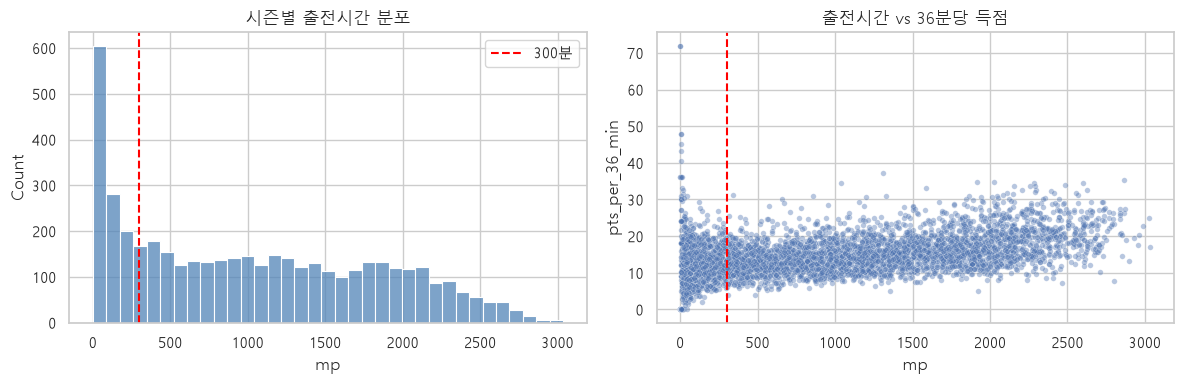

,전처리 단계,남은 행 수,직전 단계 대비 감소
0,원본 전체,32256,—
1,2019~2026 NBA,5758,26498.0
2,선수-시즌 중복 처리,4466,1292.0
3,시즌 300분 이상,3308,1158.0


제거가 아니라 기준 미충족으로 분석에서 제외된 기록: 1158


In [7]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.histplot(data=season_df, x='mp', bins=35, ax=axes[0], color='#5285b8')
axes[0].axvline(MIN_SEASON_MINUTES,color='red',linestyle='--',label=f'{MIN_SEASON_MINUTES}분')
axes[0].set_title('시즌별 출전시간 분포');axes[0].legend()
sns.scatterplot(data=season_df, x='mp', y='pts_per_36_min', alpha=.4, s=16,ax=axes[1])
axes[1].axvline(MIN_SEASON_MINUTES,color='red',linestyle='--')
axes[1].set_title('출전시간 vs 36분당 득점')
plt.tight_layout();plt.show()

season_ready = season_df.loc[season_df['mp']>=MIN_SEASON_MINUTES].copy()
audit = pd.DataFrame([
    ['원본 전체',len(raw)],
    ['2019~2026 NBA',len(nba)],
    ['선수-시즌 중복 처리',len(season_df)],
    [f'시즌 {MIN_SEASON_MINUTES}분 이상',len(season_ready)],
],columns=['전처리 단계','남은 행 수'])
audit['직전 단계 대비 감소'] = audit['남은 행 수'].shift(1)-audit['남은 행 수']
display(audit.fillna('—'))
print('제거가 아니라 기준 미충족으로 분석에서 제외된 기록:', len(season_df)-len(season_ready))

In [8]:
quality_table=pd.DataFrame({
    '단계':['전체 원본','NBA 2019~2026','선수-시즌당 한 행','시즌 300분 이상','2026년 추천 대상'],
    '건수':[len(raw),len(nba),len(season_df),len(season_ready),len(active)] if 'active' in globals() else [len(raw),len(nba),len(season_df),len(season_ready),int((season_ready['season']==END_SEASON).sum())]
})
quality_table['직전 단계 대비 감소']=quality_table['건수'].shift(1)-quality_table['건수']
display(quality_table.fillna('—'))
print(f'원본 대비 시즌·리그 필터 보존율: {len(nba)/len(raw):.1%}')
print(f'동일 선수-시즌 중복 기록: {len(nba)-len(season_df):,}행 정리')
print(f'출전 시간 조건으로 제외한 선수-시즌: {len(season_df)-len(season_ready):,}행 ({1-len(season_ready)/len(season_df):.1%})')
print('재현성 확인: (season, player_id) 중복',int(season_df.duplicated(['season','player_id']).sum()),'개')
assert not season_ready.duplicated(['season','player_id']).any()

,단계,건수,직전 단계 대비 감소
0,전체 원본,32256,—
1,NBA 2019~2026,5758,26498.0
2,선수-시즌당 한 행,4466,1292.0
3,시즌 300분 이상,3308,1158.0
4,2026년 추천 대상,435,2873.0


원본 대비 시즌·리그 필터 보존율: 17.9%
동일 선수-시즌 중복 기록: 1,292행 정리
출전 시간 조건으로 제외한 선수-시즌: 1,158행 (25.9%)
재현성 확인: (season, player_id) 중복 0 개


모델 입력 Feature: 10 개


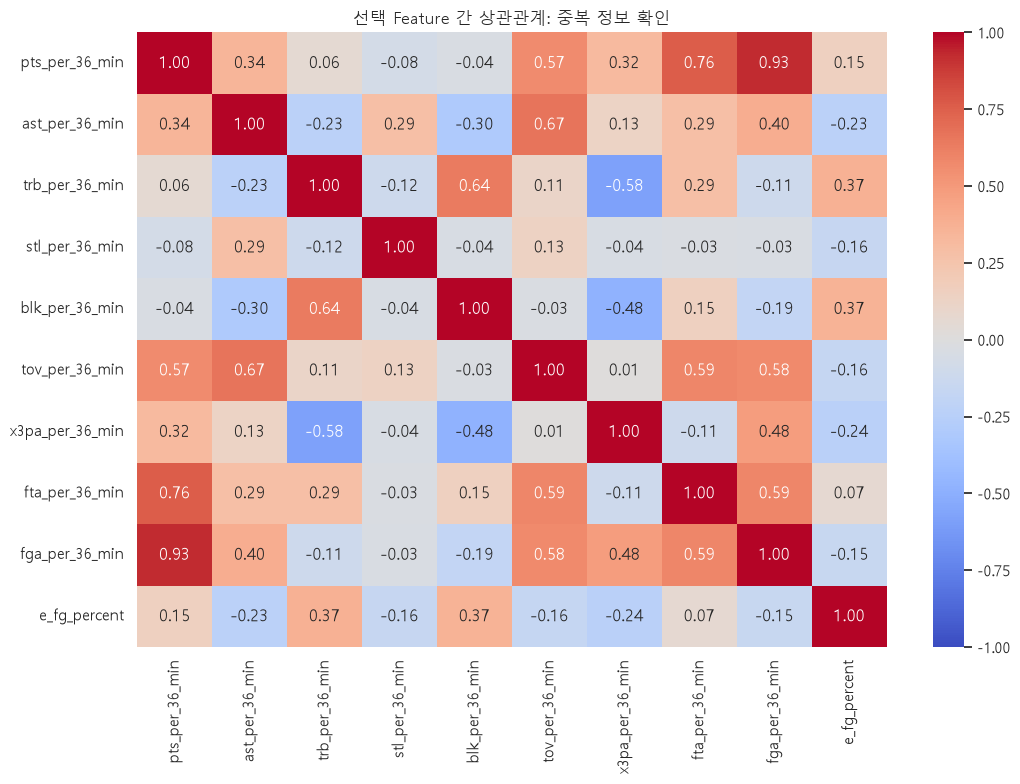

상관계수 |r| ≥ 0.85인 변수쌍 (자동 삭제하지 않고 해석):


,,절대 상관계수
pts_per_36_min,fga_per_36_min,0.926691


In [9]:
FEATURES = [
    'pts_per_36_min',   # 득점 생산량
    'ast_per_36_min',   # 공격 전개
    'trb_per_36_min',   # 리바운드
    'stl_per_36_min',   # 스틸
    'blk_per_36_min',   # 블록
    'tov_per_36_min',   # 턴오버
    'x3pa_per_36_min',  # 3점 시도 빈도
    'fta_per_36_min',   # 자유투 시도 빈도
    'fga_per_36_min',   # 전체 슛 시도 빈도
    'e_fg_percent',     # 유효 필드골 성공률
]
print('모델 입력 Feature:',len(FEATURES),'개')
corr = season_ready[FEATURES].corr()
plt.figure(figsize=(11,8))
sns.heatmap(corr,annot=True,fmt='.2f',cmap='coolwarm',vmin=-1,vmax=1)
plt.title('선택 Feature 간 상관관계: 중복 정보 확인')
plt.tight_layout();plt.show()
upper = corr.abs().where(np.triu(np.ones(corr.shape),k=1).astype(bool))
strong_pairs = upper.stack().loc[lambda x:x>=.85].sort_values(ascending=False)
print('상관계수 |r| ≥ 0.85인 변수쌍 (자동 삭제하지 않고 해석):')
display(strong_pairs.rename('절대 상관계수').to_frame() if len(strong_pairs) else pd.DataFrame({'결과':['해당 없음']}))

In [10]:
def weighted_player_summary(data, decay=RECENT_DECAY):
    """선수별로 여러 시즌을 1개 기록으로 통합. 결과 저장 X (DataFrame 반환)."""
    rows=[]
    for pid, group in data.groupby('player_id'):
        group=group.sort_values('season')
        latest=group.iloc[-1]
        # 최신 시즌에 가까울수록 비중 증가; 시즌 총 출전시간도 반영
        base_w=group['mp'].to_numpy(dtype=float)*(decay**(END_SEASON-group['season'].to_numpy()))
        row={'player_id':pid, 'player':latest['player'],
             'last_season':int(latest['season']),
             'n_seasons':int(len(group)), 'minutes_8y':float(group['mp'].sum()),
             'pos_2026':np.nan}
        for feat in FEATURES:
            values=group[feat].to_numpy(dtype=float)
            weights=base_w.copy()
            if feat=='e_fg_percent':
                # eFG%는 슛 시도가 많았던 시즌의 비율이 더 대표적임(근사치)
                weights=weights*group['fga_per_36_min'].fillna(0).to_numpy(dtype=float)/36.
            valid=np.isfinite(values)&np.isfinite(weights)&(weights>0)
            row[feat]=np.average(values[valid],weights=weights[valid]) if valid.any() else np.nan
        rows.append(row)
    return pd.DataFrame(rows)

player_history = weighted_player_summary(season_ready)
print('8시즌 기록 통합:',len(season_ready),'선수-시즌 →',len(player_history),'고유 선수')
display(player_history.head())

8시즌 기록 통합: 3308 선수-시즌 → 892 고유 선수


,player_id,player,last_season,n_seasons,minutes_8y,pos_2026,pts_per_36_min,ast_per_36_min,trb_per_36_min,stl_per_36_min,blk_per_36_min,tov_per_36_min,x3pa_per_36_min,fta_per_36_min,fga_per_36_min,e_fg_percent
0,abrinal01,Álex Abrines,2019,1,588.0,NaN,10.100000,1.200000,2.900000,1.000000,0.400000,0.900000,7.800000,0.800000,9.600000,0.487000
1,achiupr01,Precious Achiuwa,2026,6,8141.0,NaN,13.937561,1.906939,10.229319,1.144054,1.146238,1.587498,2.117696,2.877452,11.572676,0.528282
2,adamsja01,Jaylen Adams,2019,1,428.0,NaN,9.100000,5.500000,5.000000,1.200000,0.400000,2.400000,6.200000,0.800000,9.300000,0.459000
3,adamsst01,Steven Adams,2026,7,10610.0,NaN,11.098138,2.996155,13.239242,1.181773,1.159914,2.032000,0.037330,3.861952,8.067100,0.568960
4,adebaba01,Bam Adebayo,2026,8,18351.0,NaN,20.207051,4.091245,10.536193,1.287152,0.869424,2.340587,2.273655,5.621182,15.055827,0.527440


In [11]:
season_2026=season_ready.loc[season_ready['season']==END_SEASON,
                              ['player_id','player','pos','mp','age']].copy()
season_2026=season_2026.rename(columns={'pos':'pos_2026','mp':'mp_2026','age':'age_2026'})
# 합산(2TM,3TM 등)을 제외한 실제 팀들의 고유 개수
teams_2026=(nba.loc[(nba['season']==END_SEASON)&(~nba['is_total_row'])]
            .groupby('player_id')['team'].agg(lambda v: sorted(set(v))))
team_count=teams_2026.apply(len)
team_unique=teams_2026.apply(lambda teams: teams[0] if len(teams)==1 else np.nan)
season_2026['single_team_2026']=season_2026['player_id'].map(team_unique)
season_2026['team_count_2026']=season_2026['player_id'].map(team_count)
active=season_2026.merge(player_history.drop(columns=['player','pos_2026']),on='player_id',how='inner')
assert active['player_id'].is_unique
assert TARGET_PLAYER_ID in active['player_id'].values, '이탈 선수가 2026시즌 출전 기준을 충족하지 않음. 대상 또는 기준 변경 필요'
selected=active.loc[active['player_id'].eq(TARGET_PLAYER_ID)].iloc[0]
assert selected['single_team_2026']==OUR_TEAM, '설정한 우리 팀 코드와 선수의 CSV상 단일 소속팀이 일치하지 않음'
print('2026시즌 기준 출전 시간 충족 선수:',len(active),'명')
print('그중 소속팀이 하나로 확인되는 선수:',active['single_team_2026'].notna().sum(),'명')
print('가상 이탈 선수:',selected['player'],'/',selected['pos_2026'],'/',selected['single_team_2026'])
display(active.loc[active['single_team_2026'].eq(OUR_TEAM),
                   ['player','pos_2026','mp_2026','n_seasons']].sort_values('mp_2026',ascending=False).head(20))

2026시즌 기준 출전 시간 충족 선수: 435 명
그중 소속팀이 하나로 확인되는 선수: 377 명
가상 이탈 선수: Stephen Curry / PG / GSW


,player,pos_2026,mp_2026,n_seasons
298,Brandin Podziemski,SG,2333,3
138,Draymond Green,PF,1869,8
266,Moses Moody,SG,1540,5
338,Gui Santos,PF,1395,2
326,Will Richard,SG,1377,1
85,Stephen Curry,PG,1329,7
367,Pat Spencer,PG,1229,1
49,Jimmy Butler,SF,1182,8
306,Quinten Post,PF,1159,2
291,Gary Payton II,SG,1142,6


In [12]:
imputer_cluster=SimpleImputer(strategy='median')
scaler_cluster=StandardScaler()
X_cluster_imputed=imputer_cluster.fit_transform(active[FEATURES])
X_cluster=scaler_cluster.fit_transform(X_cluster_imputed)
print('군집화 입력:',X_cluster.shape)
print('입력 결측치:',int(active[FEATURES].isna().sum().sum()),
      '→ 중앙값 대체 후:',int(np.isnan(X_cluster).sum()))
display(pd.DataFrame(X_cluster,columns=FEATURES).agg(['mean','std']).round(2))

군집화 입력: (435, 10)
입력 결측치: 0 → 중앙값 대체 후: 0


,pts_per_36_min,ast_per_36_min,trb_per_36_min,stl_per_36_min,blk_per_36_min,tov_per_36_min,x3pa_per_36_min,fta_per_36_min,fga_per_36_min,e_fg_percent
mean,0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


,K,Inertia,Silhouette,최소군집인원,최소군집비율,5% 이상 군집
0,2,3302.0557,0.2254,167,0.3839,True
1,3,2597.2452,0.2558,70,0.1609,True
2,4,2314.6160,0.2098,72,0.1655,True
3,5,2099.9289,0.1805,67,0.1540,True
4,6,1959.6059,0.1755,46,0.1057,True
5,7,1859.6966,0.1637,43,0.0989,True
6,8,1768.8856,0.1480,31,0.0713,True
7,9,1692.2628,0.1640,20,0.0460,False


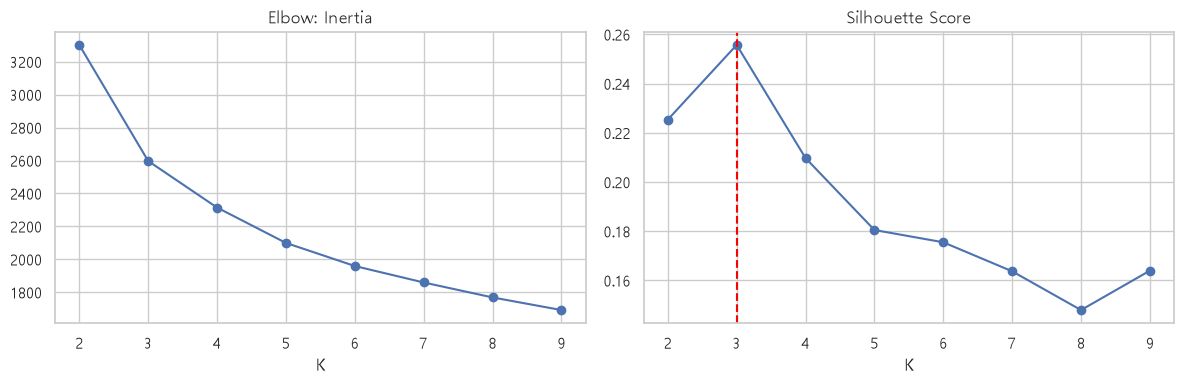

선정한 전체 선수 K: 3


In [13]:
def choose_k(X, low=2, high=9, min_group=0.05):
    output=[]
    for k in range(low,min(high,len(X)-1)+1):
        km=KMeans(n_clusters=k, n_init=15, random_state=RANDOM_STATE)
        labels=km.fit_predict(X)
        sizes=pd.Series(labels).value_counts()
        output.append({'K':k,'Inertia':km.inertia_,
                       'Silhouette':silhouette_score(X,labels),
                       '최소군집인원':int(sizes.min()),
                       '최소군집비율':sizes.min()/len(labels),
                       '5% 이상 군집':bool(sizes.min()/len(labels)>=min_group)})
    results=pd.DataFrame(output)
    eligible=results.loc[results['5% 이상 군집']]
    if eligible.empty: eligible=results
    best=int(eligible.sort_values(['Silhouette','K'],ascending=[False,True]).iloc[0]['K'])
    return results,best

k_results,best_k=choose_k(X_cluster,high=9)
display(k_results.round(4))
fig, ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(k_results['K'],k_results['Inertia'],marker='o');ax[0].set_title('Elbow: Inertia');ax[0].set_xlabel('K')
ax[1].plot(k_results['K'],k_results['Silhouette'],marker='o');ax[1].axvline(best_k,color='red',linestyle='--')
ax[1].set_title('Silhouette Score');ax[1].set_xlabel('K')
plt.tight_layout();plt.show()
print('선정한 전체 선수 K:',best_k)

전체 군집별 인원:


,인원
global_cluster,
0,127
1,70
2,238


군집별 Feature 평균:


,pts_per_36_min,ast_per_36_min,trb_per_36_min,stl_per_36_min,blk_per_36_min,tov_per_36_min,x3pa_per_36_min,fta_per_36_min,fga_per_36_min,e_fg_percent
global_cluster,,,,,,,,,,
0,21.32,5.15,6.27,1.18,0.62,2.73,6.13,4.73,16.52,0.53
1,14.77,2.22,11.01,1.00,1.75,1.76,1.63,3.45,10.30,0.61
2,13.80,3.34,5.62,1.29,0.56,1.63,5.69,2.21,11.32,0.54


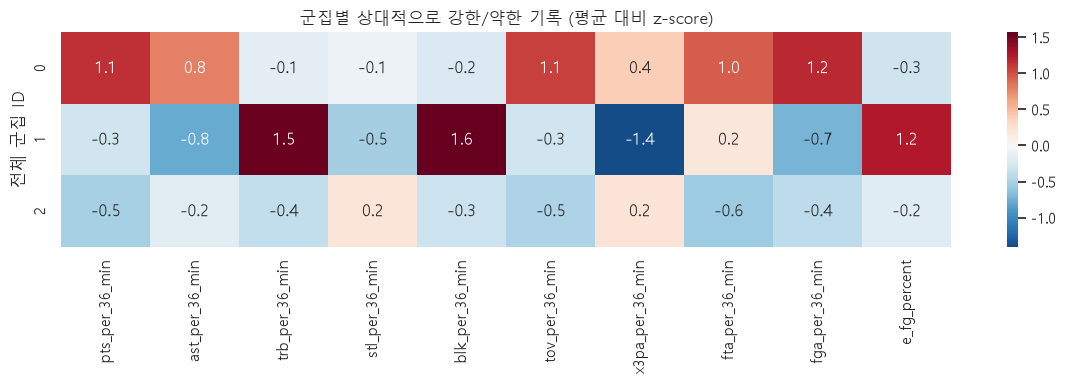

In [14]:
kmeans_all=KMeans(n_clusters=best_k,n_init=30,random_state=RANDOM_STATE)
active['global_cluster']=kmeans_all.fit_predict(X_cluster)
profile_global=active.groupby('global_cluster')[FEATURES].mean()
size_global=active.groupby('global_cluster').size().rename('인원')
print('전체 군집별 인원:');display(size_global.to_frame())
print('군집별 Feature 평균:');display(profile_global.round(2))
# 원래 단위가 서로 달라 패턴 비교가 어려우므로 군집별 평균을 z-score로 표시
z_profile=(profile_global - active[FEATURES].mean())/active[FEATURES].std(ddof=0)
plt.figure(figsize=(12,4))
sns.heatmap(z_profile,annot=True,fmt='.1f',cmap='RdBu_r',center=0)
plt.title('군집별 상대적으로 강한/약한 기록 (평균 대비 z-score)')
plt.ylabel('전체 군집 ID');plt.tight_layout();plt.show()

In [15]:
FEATURE_KR={'pts_per_36_min':'득점','ast_per_36_min':'어시스트','trb_per_36_min':'리바운드',
            'stl_per_36_min':'스틸','blk_per_36_min':'블록','tov_per_36_min':'턴오버',
            'x3pa_per_36_min':'3점 시도','fta_per_36_min':'자유투 시도',
            'fga_per_36_min':'슛 시도','e_fg_percent':'eFG%'}
profile_rows=[]
for cl in sorted(active['global_cluster'].unique()):
    z=z_profile.loc[cl].sort_values(ascending=False)
    profile_rows.append({'군집':cl,'인원':int((active['global_cluster']==cl).sum()),
                         '상대적으로 높은 특징':', '.join(f'{FEATURE_KR[k]}({v:+.2f}σ)' for k,v in z.head(3).items()),
                         '상대적으로 낮은 특징':', '.join(f'{FEATURE_KR[k]}({v:+.2f}σ)' for k,v in z.tail(2).items())})
profile_interpretation=pd.DataFrame(profile_rows)
display(profile_interpretation)
pos_mix=pd.crosstab(active['global_cluster'],active['pos_2026'],normalize='index').mul(100).round(1)
print('군집 내부 포지션 분포(%, 행 기준):')
display(pos_mix)
assert pos_mix.shape[0]==best_k

,군집,인원,상대적으로 높은 특징,상대적으로 낮은 특징
0,0,127,"슛 시도(+1.18σ), 득점(+1.14σ), 턴오버(+1.07σ)","블록(-0.24σ), eFG%(-0.32σ)"
1,1,70,"블록(+1.57σ), 리바운드(+1.54σ), eFG%(+1.25σ)","어시스트(-0.79σ), 3점 시도(-1.41σ)"
2,2,238,"3점 시도(+0.21σ), 스틸(+0.20σ), 어시스트(-0.19σ)","득점(-0.52σ), 자유투 시도(-0.56σ)"


군집 내부 포지션 분포(%, 행 기준):


pos_2026,C,PF,PG,SF,SG
global_cluster,,,,,
0,13.4,14.2,33.9,18.1,20.5
1,81.4,17.1,0.0,1.4,0.0
2,2.9,22.3,13.9,23.5,37.4


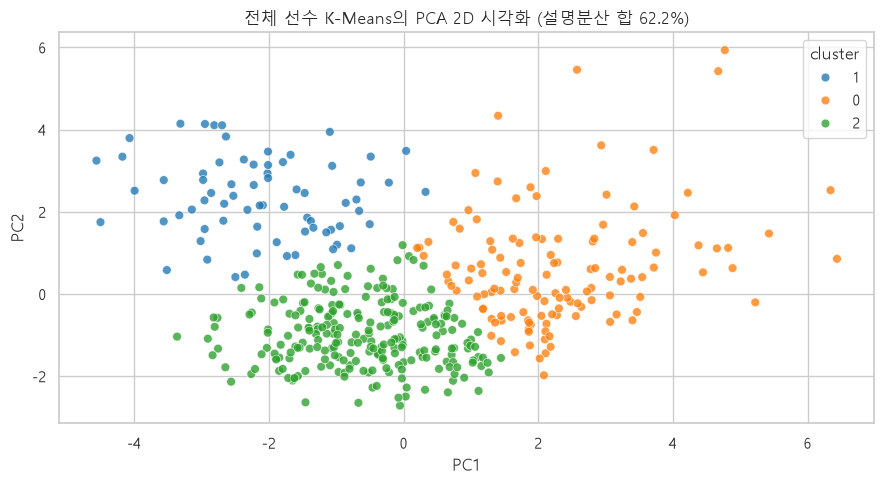

In [16]:
pca=PCA(n_components=2,random_state=RANDOM_STATE)
xy=pca.fit_transform(X_cluster)
plot_df=pd.DataFrame({'PC1':xy[:,0],'PC2':xy[:,1],'cluster':active['global_cluster'].astype(str)})
plt.figure(figsize=(9,5))
sns.scatterplot(data=plot_df,x='PC1',y='PC2',hue='cluster',palette='tab10',alpha=.78,s=40)
plt.title(f'전체 선수 K-Means의 PCA 2D 시각화 (설명분산 합 {pca.explained_variance_ratio_.sum():.1%})')
plt.tight_layout();plt.show()

In [17]:
gmm=GaussianMixture(n_components=best_k,covariance_type='diag',n_init=3,random_state=RANDOM_STATE)
gmm_labels=gmm.fit_predict(X_cluster)
gmm_result=pd.DataFrame({
    '알고리즘':['K-Means','GMM (diag)'],
    '군집 수':[best_k,best_k],
    'Silhouette':[silhouette_score(X_cluster,active['global_cluster']),
                  silhouette_score(X_cluster,gmm_labels)],
    'BIC (GMM 전용)':[np.nan,gmm.bic(X_cluster)]})
display(gmm_result.round(3))
print('K-Means vs GMM 군집 구분의 ARI:',round(adjusted_rand_score(active['global_cluster'],gmm_labels),3))
# K-Means 자체 안정성도 seed를 바꿔 확인
seed_labels=[KMeans(n_clusters=best_k,n_init=15,random_state=s).fit_predict(X_cluster) for s in [7,21,42]]
ari_stability=[adjusted_rand_score(seed_labels[i],seed_labels[j]) for i,j in [(0,1),(0,2),(1,2)]]
print('K-Means seed별 결과 일치도 (ARI) 평균:',round(float(np.mean(ari_stability)),3))

,알고리즘,군집 수,Silhouette,BIC (GMM 전용)
0,K-Means,3,0.256,NaN
1,GMM (diag),3,0.245,10802.979


K-Means vs GMM 군집 구분의 ARI: 0.849
K-Means seed별 결과 일치도 (ARI) 평균: 1.0


In [18]:
target_pos=selected['pos_2026']
role_df=active.loc[active['pos_2026'].eq(target_pos)].copy().reset_index(drop=True)
role_imputer=SimpleImputer(strategy='median')
role_scaler=StandardScaler()
role_X=role_scaler.fit_transform(role_imputer.fit_transform(role_df[FEATURES]))
role_k_results,role_best_k=choose_k(role_X,low=2,high=min(6,len(role_df)-2),min_group=.08)
display(role_k_results.round(3))
role_model=KMeans(n_clusters=role_best_k,n_init=30,random_state=RANDOM_STATE)
role_df['role_cluster']=role_model.fit_predict(role_X)
target_role_cluster=int(role_df.loc[role_df['player_id'].eq(TARGET_PLAYER_ID),'role_cluster'].iloc[0])
print('분석 포지션:',target_pos,'/',len(role_df),'명')
print('포지션 내 최적 K:',role_best_k)
print('이탈 선수의 세부 군집:',target_role_cluster)
display(role_df.groupby('role_cluster').agg(인원=('player_id','size'),
             득점=('pts_per_36_min','mean'),어시스트=('ast_per_36_min','mean'),
             리바운드=('trb_per_36_min','mean'),삼점시도=('x3pa_per_36_min','mean')).round(2))

,K,Inertia,Silhouette,최소군집인원,최소군집비율,5% 이상 군집
0,2,579.388,0.213,25,0.329,True
1,3,505.346,0.190,11,0.145,True
2,4,441.902,0.167,10,0.132,True
3,5,398.474,0.160,8,0.105,True
4,6,363.296,0.156,8,0.105,True


분석 포지션: PG / 76 명
포지션 내 최적 K: 2
이탈 선수의 세부 군집: 0


,인원,득점,어시스트,리바운드,삼점시도
role_cluster,,,,,
0,25,22.96,7.03,5.09,7.00
1,51,14.95,5.98,4.48,5.84


In [19]:
role_sil=silhouette_score(role_X,role_df['role_cluster'])
role_profile=role_df.groupby('role_cluster')[FEATURES].mean().round(2)
role_counts=role_df['role_cluster'].value_counts().sort_index()
print(f'{target_pos} 세부 군집 평가: Silhouette = {role_sil:.3f} / K = {role_best_k}')
display(role_counts.rename('군집 인원').to_frame())
display(role_profile.rename(columns=FEATURE_KR))
role_target_stats=role_profile.loc[target_role_cluster]
contrast=pd.DataFrame({'타겟 군집 평균':role_target_stats, '다른 군집 평균':role_profile.drop(index=target_role_cluster).mean()})
contrast['차이']=contrast['타겟 군집 평균']-contrast['다른 군집 평균']
print('타겟 군집의 강점·차이 (다른 군집과의 차이):')
display(contrast.rename(index=FEATURE_KR).round(2).sort_values('차이',ascending=False))

PG 세부 군집 평가: Silhouette = 0.213 / K = 2


,군집 인원
role_cluster,
0,25
1,51


,득점,어시스트,리바운드,스틸,블록,턴오버,3점 시도,자유투 시도,슛 시도,eFG%
role_cluster,,,,,,,,,,
0,22.96,7.03,5.09,1.30,0.43,3.17,7.00,5.27,17.86,0.52
1,14.95,5.98,4.48,1.44,0.40,2.31,5.84,2.38,12.64,0.52


타겟 군집의 강점·차이 (다른 군집과의 차이):


,타겟 군집 평균,다른 군집 평균,차이
득점,22.96,14.95,8.01
슛 시도,17.86,12.64,5.22
자유투 시도,5.27,2.38,2.89
3점 시도,7.00,5.84,1.16
어시스트,7.03,5.98,1.05
턴오버,3.17,2.31,0.86
리바운드,5.09,4.48,0.61
블록,0.43,0.40,0.03
eFG%,0.52,0.52,0.00
스틸,1.30,1.44,-0.14


In [20]:
def recommend_from_role(role_table, role_standardized, target_id, our_team, top_n=5):
    """포지션 세부 군집 내, 타팀 단일소속 선수만 추천."""
    target_mask=role_table['player_id'].eq(target_id).to_numpy()
    assert target_mask.sum()==1, '타겟이 포지션군 내 유일하게 존재해야 합니다.'
    target_cluster=role_table.loc[target_mask,'role_cluster'].iloc[0]
    valid=(role_table['role_cluster'].eq(target_cluster) &
           role_table['single_team_2026'].notna() &
           role_table['single_team_2026'].ne(our_team) &
           role_table['player_id'].ne(target_id))
    cand_pos=np.flatnonzero(valid.to_numpy())
    distances=pairwise_distances(role_standardized[cand_pos],
                                 role_standardized[target_mask],metric='euclidean').ravel()
    result=role_table.iloc[cand_pos].copy()
    result['distance']=distances
    return result.sort_values('distance',ascending=True).head(top_n)

recommendations=recommend_from_role(role_df,role_X,TARGET_PLAYER_ID,OUR_TEAM,TOP_N)
recommendations=recommendations.copy()
recommendations.insert(0,'rank',range(1,len(recommendations)+1))
print('이탈 선수:',selected['player'],'/',OUR_TEAM,'/',target_pos)
print('동일 세부 군집의 유효 타팀 선수 수:',int((
    role_df['role_cluster'].eq(target_role_cluster)&
    role_df['single_team_2026'].notna()&
    role_df['single_team_2026'].ne(OUR_TEAM)&
    role_df['player_id'].ne(TARGET_PLAYER_ID)).sum()))
display(recommendations[['rank','player','single_team_2026','pos_2026',
                         'mp_2026','n_seasons','role_cluster','distance']].round(3))

이탈 선수: Stephen Curry / GSW / PG
동일 세부 군집의 유효 타팀 선수 수: 20


,rank,player,single_team_2026,pos_2026,mp_2026,n_seasons,role_cluster,distance
56,1,Jordan Poole,NOP,PG,933,7,0,3.480
2,2,LaMelo Ball,CHO,PG,2017,6,0,3.532
52,3,Jamal Murray,DEN,PG,2652,7,0,3.808
63,4,D'Angelo Russell,DAL,PG,495,8,0,3.929
45,5,Tyrese Maxey,PHI,PG,2661,6,0,4.080


이탈 선수 vs 1순위 후보: 최근 가중 통합 기록


player,Stephen Curry,Jordan Poole
pts_per_36_min,29.343,22.312
ast_per_36_min,6.115,5.049
trb_per_36_min,5.184,3.466
stl_per_36_min,1.180,1.118
blk_per_36_min,0.413,0.423
tov_per_36_min,3.257,3.119
x3pa_per_36_min,12.672,9.778
fta_per_36_min,5.206,4.529
fga_per_36_min,21.010,17.888
e_fg_percent,0.583,0.513


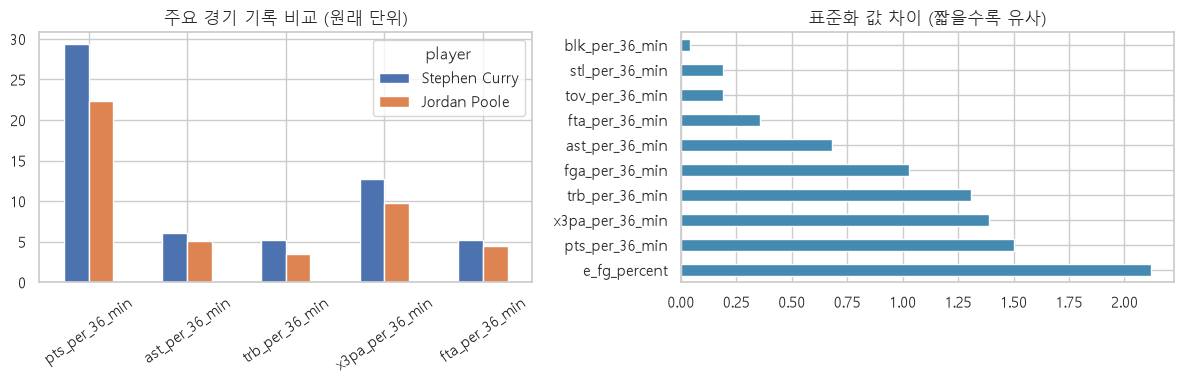

가장 비슷한 Feature 3개: ['blk_per_36_min', 'stl_per_36_min', 'tov_per_36_min']


In [21]:
if len(recommendations)>0:
    top_id=recommendations.iloc[0]['player_id']
    compare=(role_df.set_index('player_id').loc[[TARGET_PLAYER_ID,top_id],['player']+FEATURES]
             .set_index('player').T)
    print('이탈 선수 vs 1순위 후보: 최근 가중 통합 기록')
    display(compare.round(3))
    fig,axs=plt.subplots(1,2,figsize=(12,4))
    main=['pts_per_36_min','ast_per_36_min','trb_per_36_min','x3pa_per_36_min','fta_per_36_min']
    compare.loc[main].plot(kind='bar',ax=axs[0]);axs[0].set_title('주요 경기 기록 비교 (원래 단위)');axs[0].tick_params(axis='x',rotation=35)
    tgt_z=role_X[role_df['player_id'].eq(TARGET_PLAYER_ID).to_numpy()][0]
    top_z=role_X[role_df['player_id'].eq(top_id).to_numpy()][0]
    gap=pd.Series(abs(tgt_z-top_z),index=FEATURES).sort_values()
    gap.plot(kind='barh',ax=axs[1],color='#458ab0');axs[1].set_title('표준화 값 차이 (짧을수록 유사)')
    axs[1].invert_yaxis();plt.tight_layout();plt.show()
    print('가장 비슷한 Feature 3개:',gap.head(3).index.to_list())
else:
    print('동일 세부 군집에 추천 가능한 타팀 선수가 없습니다. 기준을 재검토하세요.')

In [22]:
same_pos_candidates=(role_df['single_team_2026'].notna() &
                     role_df['single_team_2026'].ne(OUR_TEAM) &
                     role_df['player_id'].ne(TARGET_PLAYER_ID))
role_target_ix=np.flatnonzero(role_df['player_id'].eq(TARGET_PLAYER_ID).to_numpy())
base_ix=np.flatnonzero(same_pos_candidates.to_numpy())
base_candidates=role_df.iloc[base_ix].copy()
base_candidates['distance']=pairwise_distances(role_X[base_ix],role_X[role_target_ix],metric='euclidean').ravel()
baseline_recommendations=base_candidates.sort_values('distance').head(TOP_N).copy()
baseline_recommendations.insert(0,'rank',range(1,len(baseline_recommendations)+1))
print('군집 제한 없는 PG 전체 거리기준 TOP 5')
display(baseline_recommendations[['rank','player','single_team_2026','role_cluster','distance']].round(3))
print('군집화 활용 TOP 5')
display(recommendations[['rank','player','single_team_2026','role_cluster','distance']].round(3))
rec_ids=set(recommendations['player_id'])
base_ids=set(baseline_recommendations['player_id'])
overlap_count=len(rec_ids&base_ids)
print(f'두 방법의 추천 후보 공통 인원: {overlap_count}/{TOP_N}')
print('군집 제한 대상 수:',sum(role_df['role_cluster'].eq(target_role_cluster)&same_pos_candidates),
      '/ 동일 포지션 타구단 대상:',int(same_pos_candidates.sum()))
# 절대 정확도는 평가할 수 없으므로 '추천 후보의 거리 수준'으로 차이를 설명
print(f'군집화 추천 1위 거리: {recommendations["distance"].iloc[0]:.3f} / 제한 없는 추천 1위 거리: {baseline_recommendations["distance"].iloc[0]:.3f}')

군집 제한 없는 PG 전체 거리기준 TOP 5


,rank,player,single_team_2026,role_cluster,distance
56,1,Jordan Poole,NOP,0,3.480
2,2,LaMelo Ball,CHO,0,3.532
52,3,Jamal Murray,DEN,0,3.808
63,4,D'Angelo Russell,DAL,0,3.929
36,5,Bones Hyland,MIN,1,4.018


군집화 활용 TOP 5


,rank,player,single_team_2026,role_cluster,distance
56,1,Jordan Poole,NOP,0,3.480
2,2,LaMelo Ball,CHO,0,3.532
52,3,Jamal Murray,DEN,0,3.808
63,4,D'Angelo Russell,DAL,0,3.929
45,5,Tyrese Maxey,PHI,0,4.080


두 방법의 추천 후보 공통 인원: 4/5
군집 제한 대상 수: 20 / 동일 포지션 타구단 대상: 61
군집화 추천 1위 거리: 3.480 / 제한 없는 추천 1위 거리: 3.480


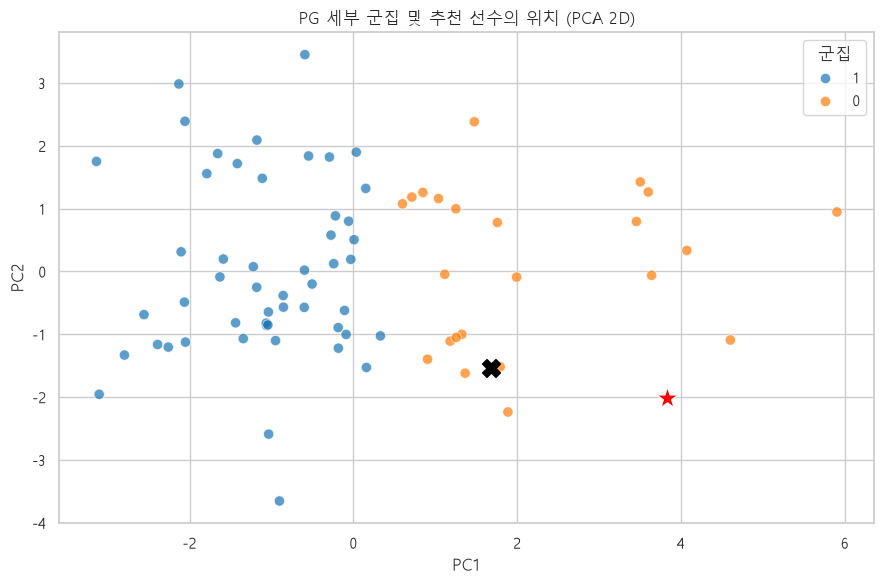

In [23]:
role_xy=PCA(n_components=2,random_state=RANDOM_STATE).fit_transform(role_X)
role_plot=pd.DataFrame({'PC1':role_xy[:,0],'PC2':role_xy[:,1],
                        '군집':role_df['role_cluster'].astype(str)})
plt.figure(figsize=(9,6))
sns.scatterplot(data=role_plot,x='PC1',y='PC2',hue='군집',palette='tab10',alpha=.72,s=55)
target_loc=np.flatnonzero(role_df['player_id'].eq(TARGET_PLAYER_ID))[0]
plt.scatter(role_xy[target_loc,0],role_xy[target_loc,1],color='red',marker='*',s=280,edgecolor='white',label='Exit player',zorder=9)
if len(recommendations):
    top_loc=np.flatnonzero(role_df['player_id'].eq(recommendations.iloc[0]['player_id']))[0]
    plt.scatter(role_xy[top_loc,0],role_xy[top_loc,1],color='black',marker='X',s=165,label='Top recommendation',zorder=9)
plt.title(f'{target_pos} 세부 군집 및 추천 선수의 위치 (PCA 2D)')
plt.tight_layout();plt.show()

In [24]:
def recommendation_at_min_minutes(min_minutes):
    data=season_df.loc[season_df['mp']>=min_minutes].copy()
    summ=weighted_player_summary(data)
    now=data.loc[data['season']==END_SEASON,['player_id','player','pos','mp']]
    if TARGET_PLAYER_ID not in now['player_id'].values:
        return {'기준(분)':min_minutes,'후보군 인원':0,'추천 TOP3':'타겟 제외'}
    now=now.rename(columns={'pos':'pos_2026','mp':'mp_2026'})
    now['single_team_2026']=now['player_id'].map(team_unique)
    role=now.merge(summ.drop(columns=['player','pos_2026']),on='player_id',how='inner')
    role=role.loc[role['pos_2026'].eq(target_pos)].reset_index(drop=True)
    arr=StandardScaler().fit_transform(SimpleImputer(strategy='median').fit_transform(role[FEATURES]))
    kres,k=choose_k(arr,low=2,high=min(6,len(role)-2),min_group=.08)
    role['role_cluster']=KMeans(n_clusters=k,n_init=30,random_state=RANDOM_STATE).fit_predict(arr)
    rec=recommend_from_role(role,arr,TARGET_PLAYER_ID,OUR_TEAM,top_n=3)
    return {'기준(분)':min_minutes,'후보군 인원':len(role),
            '군집 수 K':k,'추천 TOP3':', '.join(rec['player'].to_list())}

sensitivity=pd.DataFrame([recommendation_at_min_minutes(t) for t in [150,300,500]])
display(sensitivity)
print('해석: 추천 명단이 크게 바뀐다면 출전 기준에 민감한 모델이라는 뜻입니다.')

,기준(분),후보군 인원,군집 수 K,추천 TOP3
0,150,85,2,"LaMelo Ball, Jordan Poole, Jamal Murray"
1,300,76,2,"Jordan Poole, LaMelo Ball, Jamal Murray"
2,500,68,2,"Jordan Poole, LaMelo Ball, Jamal Murray"


해석: 추천 명단이 크게 바뀐다면 출전 기준에 민감한 모델이라는 뜻입니다.


In [25]:
CORE_FEATURES=['pts_per_36_min','ast_per_36_min','trb_per_36_min',
               'stl_per_36_min','blk_per_36_min','x3pa_per_36_min']

def rank_under_settings(decay, feats, minutes=MIN_SEASON_MINUTES):
    ready=season_df.loc[season_df['mp']>=minutes].copy()
    hist=weighted_player_summary(ready,decay=decay)
    curr=ready.loc[ready['season'].eq(END_SEASON),['player_id','player','pos','mp']].rename(
        columns={'pos':'pos_2026','mp':'mp_2026'})
    curr['single_team_2026']=curr['player_id'].map(team_unique)
    subset=curr.merge(hist.drop(columns=['player','pos_2026']),on='player_id',how='inner')
    subset=subset.loc[subset['pos_2026'].eq(target_pos)].reset_index(drop=True)
    x=StandardScaler().fit_transform(SimpleImputer(strategy='median').fit_transform(subset[feats]))
    k_values,k=choose_k(x,low=2,high=min(6,len(subset)-2),min_group=.08)
    subset['role_cluster']=KMeans(n_clusters=k,n_init=30,random_state=RANDOM_STATE).fit_predict(x)
    rec=recommend_from_role(subset,x,TARGET_PLAYER_ID,OUR_TEAM,TOP_N)
    return k,rec['player'].tolist()

robustness=[]
for d in [0.65,0.80,0.95]:
    for name,features in [('핵심6',CORE_FEATURES),('전체10',FEATURES)]:
        k,names=rank_under_settings(d,features)
        robustness.append({'최신성 가중치':d,'피처 구성':name,'세부 K':k,
                           'TOP5':', '.join(names),'기준 결과와 중복':len(set(names)&set(recommendations['player']))})
robustness_df=pd.DataFrame(robustness)
display(robustness_df)
print('기준 결과와 일치하는 추천 후보 수(평균 / 5):',round(robustness_df['기준 결과와 중복'].mean(),2))
print('해석: 기준을 바꿔도 다수 후보가 유지되면 상대적으로 안정적이며, 변경 폭이 크다면 주의를 요합니다.')

,최신성 가중치,피처 구성,세부 K,TOP5,기준 결과와 중복
0,0.65,핵심6,2,"Jordan Poole, LaMelo Ball, Bones Hyland, Tyres...",4
1,0.65,전체10,2,"Jordan Poole, LaMelo Ball, Jamal Murray, Tyres...",4
2,0.80,핵심6,3,"Jordan Poole, LaMelo Ball, Bones Hyland, D'Ang...",4
3,0.80,전체10,2,"Jordan Poole, LaMelo Ball, Jamal Murray, D'Ang...",5
4,0.95,핵심6,3,"LaMelo Ball, Luka Dončić, Cade Cunningham, Ja ...",1
5,0.95,전체10,2,"LaMelo Ball, Jordan Poole, D'Angelo Russell, J...",4


기준 결과와 일치하는 추천 후보 수(평균 / 5): 3.67
해석: 기준을 바꿔도 다수 후보가 유지되면 상대적으로 안정적이며, 변경 폭이 크다면 주의를 요합니다.


In [26]:
classification_df=season_ready.loc[season_ready['pos'].isin(['PG','SG','SF','PF','C'])].copy()
X_cls=classification_df[FEATURES]
label_encoder=LabelEncoder()
y_cls=label_encoder.fit_transform(classification_df['pos'])
groups=classification_df['player_id'].values
splitter=GroupShuffleSplit(n_splits=1,test_size=0.20,random_state=RANDOM_STATE)
train_idx,test_idx=next(splitter.split(X_cls,y_cls,groups=groups))
X_train,X_test=X_cls.iloc[train_idx],X_cls.iloc[test_idx]
y_train,y_test=y_cls[train_idx],y_cls[test_idx]
groups_train=groups[train_idx]
assert not set(groups_train).intersection(groups[test_idx]), '그룹 누수 발생'
print('학습 행:',len(X_train),' / 최종 테스트 행:',len(X_test))
print('학습 고유선수:',len(set(groups_train)),' / 최종 테스트 고유선수:',len(set(groups[test_idx])))
print('포지션 라벨 순서:',list(label_encoder.classes_))
display(pd.DataFrame({'Train':pd.Series(label_encoder.inverse_transform(y_train)).value_counts(normalize=True),
                      'Test':pd.Series(label_encoder.inverse_transform(y_test)).value_counts(normalize=True)}).round(3))

학습 행: 2603  / 최종 테스트 행: 705
학습 고유선수: 713  / 최종 테스트 고유선수: 179
포지션 라벨 순서: ['C', 'PF', 'PG', 'SF', 'SG']


,Train,Test
C,0.189,0.213
PF,0.187,0.214
PG,0.194,0.163
SF,0.197,0.149
SG,0.233,0.261


,모델,Macro F1 평균,Macro F1 표준편차,Accuracy 평균,Weighted F1 평균
0,RandomForest,0.5938,0.0199,0.5962,0.5914
1,XGBoost,0.5927,0.0054,0.5939,0.5897
2,LightGBM,0.5696,0.0149,0.5693,0.5666
3,DecisionTree,0.5415,0.0171,0.5409,0.5390


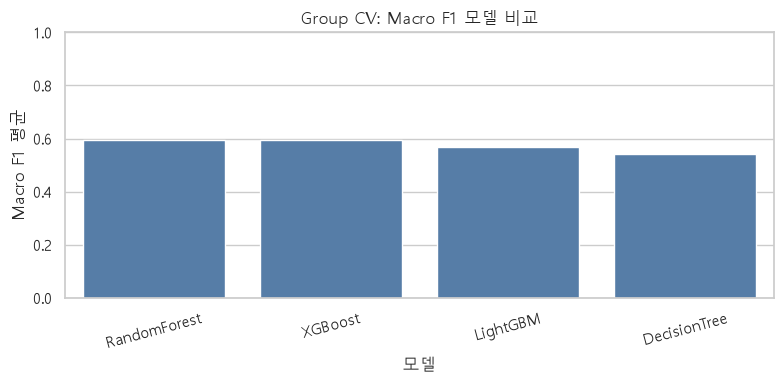

In [27]:
cv=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=RANDOM_STATE)
models={
    'DecisionTree':DecisionTreeClassifier(max_depth=7,min_samples_leaf=6,random_state=RANDOM_STATE),
    'RandomForest':RandomForestClassifier(n_estimators=180,min_samples_leaf=2,
                                           random_state=RANDOM_STATE,n_jobs=2),
    'XGBoost':XGBClassifier(n_estimators=180,max_depth=4,learning_rate=.07,
                            subsample=.85,colsample_bytree=.9,
                            objective='multi:softprob',eval_metric='mlogloss',
                            tree_method='hist',random_state=RANDOM_STATE,n_jobs=2),
    'LightGBM':LGBMClassifier(n_estimators=180,learning_rate=.06,max_depth=-1,
                              num_leaves=15,min_child_samples=20,
                              verbosity=-1,random_state=RANDOM_STATE,n_jobs=2),
}
rows=[]
for name,model in models.items():
    pipe=Pipeline([('imputer',SimpleImputer(strategy='median')),('model',model)])
    scores=cross_validate(pipe,X_train,y_train,cv=cv,groups=groups_train,
                          scoring={'macro_f1':'f1_macro','accuracy':'accuracy','weighted_f1':'f1_weighted'},
                          n_jobs=1,error_score='raise')
    rows.append({'모델':name,'Macro F1 평균':scores['test_macro_f1'].mean(),
                 'Macro F1 표준편차':scores['test_macro_f1'].std(),
                 'Accuracy 평균':scores['test_accuracy'].mean(),
                 'Weighted F1 평균':scores['test_weighted_f1'].mean()})
model_scores=pd.DataFrame(rows).sort_values('Macro F1 평균',ascending=False).reset_index(drop=True)
display(model_scores.round(4))
plt.figure(figsize=(8,4))
sns.barplot(data=model_scores,x='모델',y='Macro F1 평균',color='#487db4')
plt.ylim(0,1);plt.title('Group CV: Macro F1 모델 비교');plt.xticks(rotation=15);plt.tight_layout();plt.show()

In [28]:
winner_name=model_scores.iloc[0]['모델']
search_space={
    'DecisionTree':{'model__max_depth':[5,9,None], 'model__min_samples_leaf':[4,10]},
    'RandomForest':{'model__max_depth':[None,12], 'model__min_samples_leaf':[1,3]},
    'XGBoost':{'model__max_depth':[3,5], 'model__learning_rate':[.05,.10]},
    'LightGBM':{'model__num_leaves':[15,31], 'model__learning_rate':[.04,.08]},
}
base_pipe=Pipeline([('imputer',SimpleImputer(strategy='median')),
                    ('model',models[winner_name])])
grid=GridSearchCV(estimator=base_pipe,param_grid=search_space[winner_name],
                  cv=cv,scoring='f1_macro',n_jobs=1,refit=True,return_train_score=True)
grid.fit(X_train,y_train,groups=groups_train)
print('교차검증 1위:',winner_name)
print('최적 하이퍼파라미터:',grid.best_params_)
print('튜닝 최고 CV Macro F1:',round(grid.best_score_,4))
display(pd.DataFrame(grid.cv_results_)[['params','mean_train_score','mean_test_score','std_test_score']]
        .sort_values('mean_test_score',ascending=False).round(4))

교차검증 1위: RandomForest
최적 하이퍼파라미터: {'model__max_depth': None, 'model__min_samples_leaf': 3}
튜닝 최고 CV Macro F1: 0.5959


,params,mean_train_score,mean_test_score,std_test_score
1,"{'model__max_depth': None, 'model__min_samples...",0.9489,0.5959,0.0201
2,"{'model__max_depth': 12, 'model__min_samples_l...",0.9863,0.5941,0.0199
3,"{'model__max_depth': 12, 'model__min_samples_l...",0.9225,0.5900,0.0186
0,"{'model__max_depth': None, 'model__min_samples...",1.0000,0.5863,0.0130


최종 Test Accuracy: 0.6085
최종 Test Macro F1: 0.5977

포지션별 Precision / Recall / F1:
              precision    recall  f1-score   support

           C       0.82      0.84      0.83       150
          PF       0.51      0.43      0.47       151
          PG       0.68      0.80      0.74       115
          SF       0.30      0.37      0.33       105
          SG       0.66      0.58      0.62       184

    accuracy                           0.61       705
   macro avg       0.60      0.60      0.60       705
weighted avg       0.61      0.61      0.61       705



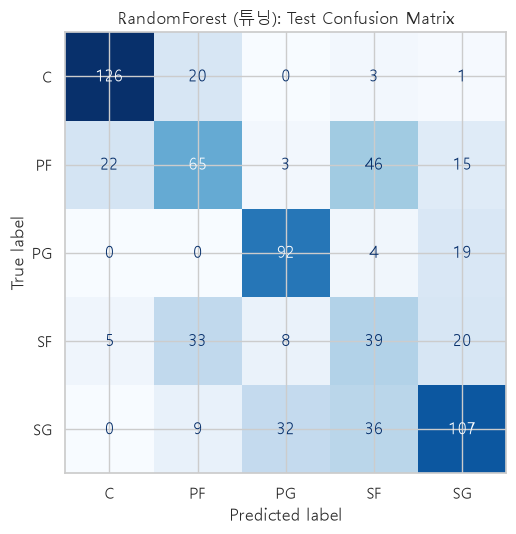

In [29]:
final_clf=grid.best_estimator_
y_pred=final_clf.predict(X_test)
print('최종 Test Accuracy:',round(accuracy_score(y_test,y_pred),4))
print('최종 Test Macro F1:',round(f1_score(y_test,y_pred,average='macro'),4))
print('\n포지션별 Precision / Recall / F1:')
print(classification_report(y_test,y_pred,labels=np.arange(len(label_encoder.classes_)),
                            target_names=label_encoder.classes_,zero_division=0))
fig,ax=plt.subplots(figsize=(6.5,5.5))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,labels=np.arange(len(label_encoder.classes_)),
                                       display_labels=label_encoder.classes_,cmap='Blues',ax=ax,
                                       colorbar=False)
ax.set_title(f'{winner_name} (튜닝): Test Confusion Matrix')
plt.tight_layout();plt.show()

In [30]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score, precision_score, recall_score, confusion_matrix
baseline_model=DummyClassifier(strategy='most_frequent')
baseline_model.fit(X_train,y_train)
baseline_pred=baseline_model.predict(X_test)
train_prediction=final_clf.predict(X_train)
metric_results=pd.DataFrame([
 {'대상':'최빈 포지션 기준','Accuracy':accuracy_score(y_test,baseline_pred),
  'Macro Precision':precision_score(y_test,baseline_pred,average='macro',zero_division=0),
  'Macro Recall':recall_score(y_test,baseline_pred,average='macro',zero_division=0),
  'Macro F1':f1_score(y_test,baseline_pred,average='macro',zero_division=0),
  'Balanced Accuracy':balanced_accuracy_score(y_test,baseline_pred)},
 {'대상':'최종 모델 (Train)','Accuracy':accuracy_score(y_train,train_prediction),
  'Macro Precision':precision_score(y_train,train_prediction,average='macro',zero_division=0),
  'Macro Recall':recall_score(y_train,train_prediction,average='macro',zero_division=0),
  'Macro F1':f1_score(y_train,train_prediction,average='macro',zero_division=0),
  'Balanced Accuracy':balanced_accuracy_score(y_train,train_prediction)},
 {'대상':'최종 모델 (Test)','Accuracy':accuracy_score(y_test,y_pred),
  'Macro Precision':precision_score(y_test,y_pred,average='macro',zero_division=0),
  'Macro Recall':recall_score(y_test,y_pred,average='macro',zero_division=0),
  'Macro F1':f1_score(y_test,y_pred,average='macro',zero_division=0),
  'Balanced Accuracy':balanced_accuracy_score(y_test,y_pred)}])
display(metric_results.round(4).set_index('대상'))
overfit_gap=f1_score(y_train,train_prediction,average='macro')-f1_score(y_test,y_pred,average='macro')
print(f'Train-Test Macro F1 격차: {overfit_gap:+.4f}')
print('참고: 격차 하나로 과적합을 단정하지 않으며 데이터 규모·분포·CV 분산도 같이 판단합니다.')
per_pos=classification_report(y_test,y_pred,output_dict=True,zero_division=0)
pos_eval=pd.DataFrame(per_pos).T.reindex([str(i) for i in range(len(label_encoder.classes_))])
pos_eval.index=label_encoder.classes_
print('포지션별 성능:')
display(pos_eval[['precision','recall','f1-score','support']].round(3))

,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy
대상,,,,,
최빈 포지션 기준,0.2610,0.0522,0.2000,0.0828,0.2000
최종 모델 (Train),0.9458,0.9469,0.9469,0.9466,0.9469
최종 모델 (Test),0.6085,0.5964,0.6047,0.5977,0.6047


Train-Test Macro F1 격차: +0.3489
참고: 격차 하나로 과적합을 단정하지 않으며 데이터 규모·분포·CV 분산도 같이 판단합니다.
포지션별 성능:


,precision,recall,f1-score,support
C,0.824,0.840,0.832,150.0
PF,0.512,0.430,0.468,151.0
PG,0.681,0.800,0.736,115.0
SF,0.305,0.371,0.335,105.0
SG,0.660,0.582,0.618,184.0


,중요도
trb_per_36_min,0.2382
ast_per_36_min,0.1902
x3pa_per_36_min,0.1179
blk_per_36_min,0.1003
e_fg_percent,0.0711
tov_per_36_min,0.0589
pts_per_36_min,0.0571
fga_per_36_min,0.0571
fta_per_36_min,0.0549
stl_per_36_min,0.0543


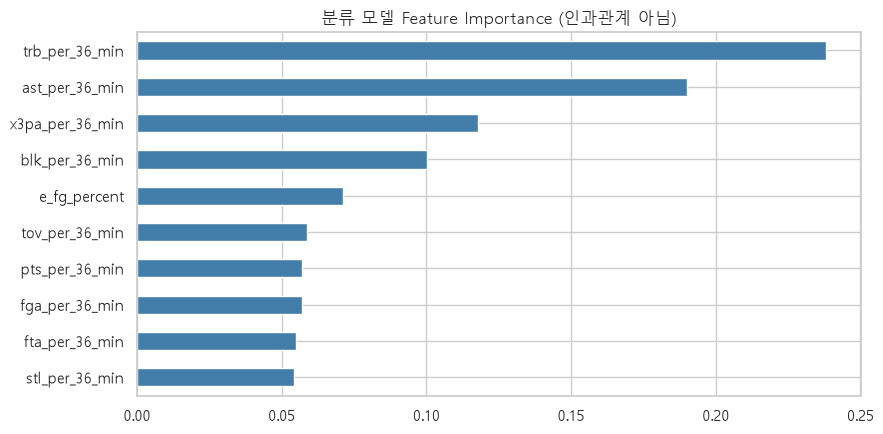

In [31]:
importance=pd.Series(final_clf.named_steps['model'].feature_importances_,index=FEATURES)
importance=importance.sort_values(ascending=False)
display(importance.rename('중요도').to_frame().round(4))
plt.figure(figsize=(9,4.5))
importance.sort_values().plot(kind='barh',color='#437daa')
plt.title('분류 모델 Feature Importance (인과관계 아님)')
plt.tight_layout();plt.show()

In [32]:
from IPython.display import Markdown

cv_winner=model_scores.iloc[0]
test_f1=f1_score(y_test,y_pred,average='macro')
test_acc=accuracy_score(y_test,y_pred)
full_sil=silhouette_score(X_cluster,active['global_cluster'])
print('='*80)
print('                    NBA 대체 선수 추천 프로젝트 — 최종 분석 결과')
print('='*80)
print(f'[데이터] 원본 {len(raw):,}행 → 2019~2026 NBA {len(nba):,}행 → 선수·시즌 {len(season_df):,}행')
print(f'[전처리] 시즌 {MIN_SEASON_MINUTES}분 이상 {len(season_ready):,}행 → 2026시즌 추천 분석 {len(active):,}명')
print(f'[전체 군집] K={best_k} | Silhouette={full_sil:.4f} | 군집 인원={size_global.to_dict()}')
print(f'[세부 군집] {target_pos} K={role_best_k} | Silhouette={role_sil:.4f} | 타겟 군집={target_role_cluster}')
print(f'[추천] {selected["player"]} 이탈 / CSV상 {OUR_TEAM} → 타팀 TOP {len(recommendations)}')
print(recommendations[['rank','player','single_team_2026','distance']].to_string(index=False))
print(f'[추천 강건성] 최신성·Feature 6개 조합 기준 TOP5 공통인원 평균 {robustness_df["기준 결과와 중복"].mean():.2f}/5')
print(f'[분류 성능] 교차검증 1위 {winner_name}, CV Macro F1={cv_winner["Macro F1 평균"]:.4f}')
print(f'[튜닝 성능] CV Macro F1={grid.best_score_:.4f}, Test Accuracy={test_acc:.4f}, Test Macro F1={test_f1:.4f}')
print(f'[과적합 점검] Train-Test Macro F1 격차={overfit_gap:+.4f}')
print('외부 CSV 생성 없음. 결과는 Jupyter 출력만 사용.')

rec_lines='\n'.join(f'{i+1}. **{r.player}** ({r.single_team_2026}) — 거리 **{r.distance:.3f}**' for i,r in enumerate(recommendations.itertuples()))
if full_sil<.3:
    group_reading='전체 Silhouette 값이 0.3 미만이므로 군집 구분이 뚜렷하지 않습니다. 군집 번호를 선수의 확정적인 유형으로 해석하면 안 됩니다.'
elif full_sil<.5:
    group_reading='군집 분리가 보통 수준입니다. 군집 내부의 기록 다양성을 함께 확인해야 합니다.'
else:
    group_reading='군집이 비교적 뚜렷하게 분리됐습니다. 그래도 모든 선수를 고정된 유형으로 단정할 수는 없습니다.'
if overfit_gap >= 0.15:
    overfit_reading=f'학습·테스트 Macro F1 격차가 {overfit_gap:.3f}으로 커서 과적합 위험이 있다. 교차검증과 Test 점수는 비슷하지만, 학습 기록에 과도하게 맞춘 점은 한계로 평가한다.'
else:
    overfit_reading=f'학습·테스트 Macro F1 격차는 {overfit_gap:.3f}이었다. 단일 분할만으로 일반화 성능을 완전히 확정할 수는 없다.'
summary=f"""### ✅ 최종 결론 — 실제 계산 결과 기반

**질문:** “{selected['player']}이(가) {OUR_TEAM}를 떠나면, 기록상 어떤 선수가 가장 유사한가?”

**답:** 2019~2026시즌 기록을 최근성·시즌 출전시간으로 가중 평균하여 2026시즌 출전 조건을 충족하는 {len(active):,}명의 스타일을 비교했다. 같은 {target_pos} 포지션의 세부 K-Means 군집(K={role_best_k}) 안에서 표준화 유클리드 거리가 작은 타팀 선수를 찾은 결과:

{rec_lines}

**분석 의미:** 이 추천은 *선수의 플레이 스타일 기록 유사성 순위*다. 군집화는 후보군을 제한하는 데 실제로 적용되었고, 후보 간 순위는 표준화 지표의 유클리드 거리로 결정되었다.

**군집화 품질:** 전체 K={best_k}, Silhouette **{full_sil:.3f}** / {target_pos} 세부 K={role_best_k}, Silhouette **{role_sil:.3f}**. {group_reading}

**추가 검증:** 군집 제한이 없는 거리 기준 추천과 비교하면 TOP5 중 **{overlap_count}/{TOP_N}명**이 겹친다. 최근성 가중치와 Feature 구성을 변경한 {len(robustness_df)}개 실험에서 기준 TOP5와 겹치는 인원은 평균 **{robustness_df['기준 결과와 중복'].mean():.2f}/{TOP_N}명**이었다. **출전시간 150·300·500분 변화**에 따른 명단 역시 위 표에서 직접 확인한다.

**분류 머신러닝:** {winner_name}의 튜닝 후 Test Accuracy **{test_acc:.1%}**, Macro F1 **{test_f1:.4f}**. 이는 포지션 예측 성능이지 추천 정확도가 아니다. Train–Test Macro F1 격차는 **{overfit_gap:+.4f}**다. {overfit_reading}

**결론:** 데이터 전처리, 두 단계 군집화, 군집 내부 거리 추천, 민감도 분석, 분류 모델 비교를 재현 가능한 노트북으로 완성했다. **외부의 실제 정답 없이 추천이 실제 팀 성적을 향상시킨다고 주장할 수는 없다.** 실제 트레이드 결정에는 연봉, 계약, 팀 전술, 부상, 현행 소속팀 정보가 추가로 필요하다.
"""
display(Markdown(summary))

                    NBA 대체 선수 추천 프로젝트 — 최종 분석 결과
[데이터] 원본 32,256행 → 2019~2026 NBA 5,758행 → 선수·시즌 4,466행
[전처리] 시즌 300분 이상 3,308행 → 2026시즌 추천 분석 435명
[전체 군집] K=3 | Silhouette=0.2558 | 군집 인원={0: 127, 1: 70, 2: 238}
[세부 군집] PG K=2 | Silhouette=0.2129 | 타겟 군집=0
[추천] Stephen Curry 이탈 / CSV상 GSW → 타팀 TOP 5
 rank           player single_team_2026  distance
    1     Jordan Poole              NOP  3.479681
    2      LaMelo Ball              CHO  3.532449
    3     Jamal Murray              DEN  3.807666
    4 D'Angelo Russell              DAL  3.929280
    5     Tyrese Maxey              PHI  4.080055
[추천 강건성] 최신성·Feature 6개 조합 기준 TOP5 공통인원 평균 3.67/5
[분류 성능] 교차검증 1위 RandomForest, CV Macro F1=0.5938
[튜닝 성능] CV Macro F1=0.5959, Test Accuracy=0.6085, Test Macro F1=0.5977
[과적합 점검] Train-Test Macro F1 격차=+0.3489
외부 CSV 생성 없음. 결과는 Jupyter 출력만 사용.


### ✅ 최종 결론 — 실제 계산 결과 기반

**질문:** “Stephen Curry이(가) GSW를 떠나면, 기록상 어떤 선수가 가장 유사한가?”

**답:** 2019~2026시즌 기록을 최근성·시즌 출전시간으로 가중 평균하여 2026시즌 출전 조건을 충족하는 435명의 스타일을 비교했다. 같은 PG 포지션의 세부 K-Means 군집(K=2) 안에서 표준화 유클리드 거리가 작은 타팀 선수를 찾은 결과:

1. **Jordan Poole** (NOP) — 거리 **3.480**
2. **LaMelo Ball** (CHO) — 거리 **3.532**
3. **Jamal Murray** (DEN) — 거리 **3.808**
4. **D'Angelo Russell** (DAL) — 거리 **3.929**
5. **Tyrese Maxey** (PHI) — 거리 **4.080**

**분석 의미:** 이 추천은 *선수의 플레이 스타일 기록 유사성 순위*다. 군집화는 후보군을 제한하는 데 실제로 적용되었고, 후보 간 순위는 표준화 지표의 유클리드 거리로 결정되었다.

**군집화 품질:** 전체 K=3, Silhouette **0.256** / PG 세부 K=2, Silhouette **0.213**. 전체 Silhouette 값이 0.3 미만이므로 군집 구분이 뚜렷하지 않습니다. 군집 번호를 선수의 확정적인 유형으로 해석하면 안 됩니다.

**추가 검증:** 군집 제한이 없는 거리 기준 추천과 비교하면 TOP5 중 **4/5명**이 겹친다. 최근성 가중치와 Feature 구성을 변경한 6개 실험에서 기준 TOP5와 겹치는 인원은 평균 **3.67/5명**이었다. **출전시간 150·300·500분 변화**에 따른 명단 역시 위 표에서 직접 확인한다.

**분류 머신러닝:** RandomForest의 튜닝 후 Test Accuracy **60.9%**, Macro F1 **0.5977**. 이는 포지션 예측 성능이지 추천 정확도가 아니다. Train–Test Macro F1 격차는 **+0.3489**다. 학습·테스트 Macro F1 격차가 0.349으로 커서 과적합 위험이 있다. 교차검증과 Test 점수는 비슷하지만, 학습 기록에 과도하게 맞춘 점은 한계로 평가한다.

**결론:** 데이터 전처리, 두 단계 군집화, 군집 내부 거리 추천, 민감도 분석, 분류 모델 비교를 재현 가능한 노트북으로 완성했다. **외부의 실제 정답 없이 추천이 실제 팀 성적을 향상시킨다고 주장할 수는 없다.** 실제 트레이드 결정에는 연봉, 계약, 팀 전술, 부상, 현행 소속팀 정보가 추가로 필요하다.


In [33]:
def recommend_player(player_name_or_id, top_n=5):
    """2026시즌 선수 이름/ID를 입력받아 타 구단의 동일 포지션·세부 군집 선수 추천."""
    query = str(player_name_or_id).strip().casefold()
    if not query:
        print('선수 이름이나 player_id를 입력해 주세요.')
        return pd.DataFrame()

    name_equal = active['player'].astype(str).str.casefold().eq(query)
    id_equal = active['player_id'].astype(str).str.casefold().eq(query)
    matched = active.loc[name_equal | id_equal].copy()
    if matched.empty:
        similar = active.loc[
            active['player'].astype(str).str.contains(str(player_name_or_id).strip(), case=False, regex=False),
            ['player', 'player_id', 'pos_2026', 'single_team_2026']
        ].head(10)
        print(f'찾을 수 없는 선수: {player_name_or_id!r}')
        if len(similar):
            print('혹시 아래 선수를 찾으셨나요?')
            display(similar)
        else:
            print('2026시즌·출전시간 기준을 충족한 선수만 검색할 수 있어요.')
        return pd.DataFrame()
    if len(matched) > 1:
        print('동명이인입니다. 아래 player_id로 다시 입력해 주세요.')
        display(matched[['player', 'player_id', 'pos_2026', 'single_team_2026']])
        return pd.DataFrame()

    target = matched.iloc[0]
    if pd.isna(target['pos_2026']):
        print('해당 선수의 2026시즌 포지션이 없어 추천할 수 없습니다.')
        return pd.DataFrame()
    if pd.isna(target['single_team_2026']):
        print('2026시즌 단일 소속팀을 확정할 수 없는 선수입니다 (시즌 중 이적 등).')
        print('현재 프로젝트에서는 임의로 팀을 지정하지 않고 추천을 중단합니다.')
        return pd.DataFrame()

    pid = target['player_id']
    pos = target['pos_2026']
    team = target['single_team_2026']
    subset = active.loc[active['pos_2026'].eq(pos)].copy().reset_index(drop=True)
    if len(subset) < 4:
        print(f'{pos} 포지션의 유효 선수 수가 너무 적어 세부 군집화를 할 수 없습니다.')
        return pd.DataFrame()

    # 기존 본문과 동일한 결측치 대체/스케일링/K선정 기준 적용
    Xi = SimpleImputer(strategy='median').fit_transform(subset[FEATURES])
    Xs = StandardScaler().fit_transform(Xi)
    _, k = choose_k(Xs, low=2, high=min(6, len(subset)-2), min_group=.08)
    subset['role_cluster'] = KMeans(
        n_clusters=k, n_init=30, random_state=RANDOM_STATE
    ).fit_predict(Xs)
    target_cluster = int(subset.loc[subset['player_id'].eq(pid), 'role_cluster'].iloc[0])

    result = recommend_from_role(subset, Xs, pid, team, top_n=top_n).copy()
    result.insert(0, 'rank', range(1, len(result)+1))
    print('=' * 58)
    print(f'이탈 선수: {target["player"]} | 원 소속팀: {team} | 포지션: {pos}')
    print(f'{pos} 선수 {len(subset)}명 세부 군집: K={k} | 이탈 선수 군집={target_cluster}')
    print(f'추천 가능한 타 구단 대체 선수: {len(result)}명 출력')
    print('=' * 58)
    if result.empty:
        print('이 선수와 동일한 세부 군집의 유효 타 구단 후보가 없습니다.')
    else:
        display(result[
            ['rank', 'player', 'single_team_2026', 'pos_2026',
             'mp_2026', 'n_seasons', 'distance']
        ].rename(columns={
            'rank':'순위', 'player':'추천 선수', 'single_team_2026':'팀',
            'pos_2026':'포지션', 'mp_2026':'2026 출전시간',
            'n_seasons':'분석 시즌 수', 'distance':'유사 거리'
        }).round(3))
    return result


In [36]:
선수_이름 = 'Shai Gilgeous-Alexander'
추천결과 = recommend_player(선수_이름, top_n=5)


이탈 선수: Shai Gilgeous-Alexander | 원 소속팀: OKC | 포지션: PG
PG 선수 76명 세부 군집: K=2 | 이탈 선수 군집=0
추천 가능한 타 구단 대체 선수: 5명 출력


,순위,추천 선수,팀,포지션,2026 출전시간,분석 시즌 수,유사 거리
24,1,De'Aaron Fox,SAS,PG,2231,8,3.514
74,2,Brandon Williams,DAL,PG,1463,3,3.949
45,3,Tyrese Maxey,PHI,PG,2661,6,4.035
52,4,Jamal Murray,DEN,PG,2652,7,4.179
16,5,Cade Cunningham,DET,PG,2172,5,4.291
